
--- First 5 Rows ---
   SalesID    Product      Region  Sales  Year
0      101  Product A       North    500  2022
1      102  Product B        East    600  2022
2      103  Product C  West Coast    700  2022
3      104  Product D       South    800  2022
4      105  Product E     Central    550  2022

--- Descriptive Statistics ---
          SalesID       Sales    Year
count    5.000000    5.000000     5.0
mean   103.000000  630.000000  2022.0
std      1.581139  120.415946     0.0
min    101.000000  500.000000  2022.0
25%    102.000000  550.000000  2022.0
50%    103.000000  600.000000  2022.0
75%    104.000000  700.000000  2022.0
max    105.000000  800.000000  2022.0

Standard Deviation:
SalesID      1.581139
Sales      120.415946
Year         0.000000
dtype: float64

Variance:
SalesID        2.5
Sales      14500.0
Year           0.0
dtype: float64


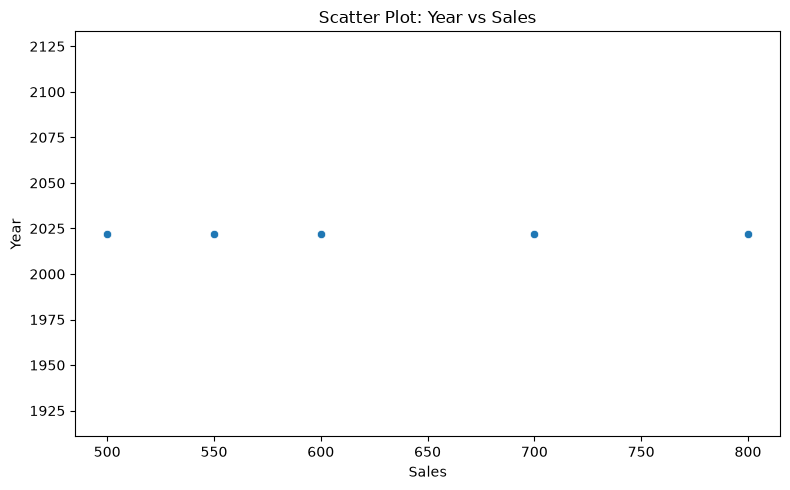

Visualization saved as scatter_plot.png successfully!


In [2]:
# %% [markdown]
# # Pandas Analyzer & Data Visualization Project
# Developed using Object-Oriented Programming principles.

# %%
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

class SalesDataAnalyzer:
    """Class encapsulating all sales data analysis and visualization functionalities."""
    
    def __init__(self):
        """Constructor to initialize data attributes."""
        self.data = None
        self.current_fig = None  # To keep track of the last created plot for saving

    def __del__(self):
        """Destructor to perform cleanup if necessary."""
        print("SalesDataAnalyzer object destroyed.")

    def load_data(self, file_path):
        """Load data from a CSV file."""
        try:
            if not os.path.exists(file_path):
                print(f"Error: File '{file_path}' not found.")
                return False
            self.data = pd.read_csv(file_path)
            print("Dataset loaded successfully!")
            return True
        except Exception as e:
            print(f"Error loading file: {e}")
            return False

    def explore_data(self, option, n=5):
        """Display basic information and views about the dataset."""
        if self.data is None:
            print("Please load the dataset first.")
            return

        if option == 1:
            print(f"\n--- First {n} Rows ---")
            display(self.data.head(n)) if 'display' in globals() else print(self.data.head(n))
        elif option == 2:
            print(f"\n--- Last {n} Rows ---")
            display(self.data.tail(n)) if 'display' in globals() else print(self.data.tail(n))
        elif option == 3:
            print("\n--- Column Names ---")
            print(list(self.data.columns))
        elif option == 4:
            print("\n--- Data Types ---")
            print(self.data.dtypes)
        elif option == 5:
            print("\n--- Dataset Info ---")
            print(self.data.info())
        else:
            print("Invalid exploration option.")

    def clean_data(self, option):
        """Handle missing values and perform data cleaning."""
        if self.data is None:
            print("Please load the dataset first.")
            return

        if option == 1:
            missing = self.data.isnull().sum()
            if missing.sum() == 0:
                print("No missing values found in the dataset!")
            else:
                print("\n--- Rows with Missing Values ---")
                print(self.data[self.data.isnull().any(axis=1)])
        elif option == 2:
            # Fill numeric missing values with mean
            numeric_cols = self.data.select_dtypes(include=[np.number]).columns
            self.data[numeric_cols] = self.data[numeric_cols].fillna(self.data[numeric_cols].mean())
            print("Missing values filled with column means successfully!")
        elif option == 3:
            initial_rows = len(self.data)
            self.data.dropna(inplace=True)
            print(f"Dropped {initial_rows - len(self.data)} rows containing missing values.")
        elif option == 4:
            print("Feature available: use custom fill implementation if needed.")
        else:
            print("Invalid cleaning option.")

    def mathematical_operations(self):
        """Perform operations, indexing, slicing, and numpy array conversions."""
        if self.data is None:
            print("Please load the dataset first.")
            return

        print("\n--- NumPy Array Conversion & Slicing Example ---")
        if 'Sales' in self.data.columns:
            sales_array = self.data['Sales'].to_numpy()
            print(f"First 5 elements of Sales Numpy Array: {sales_array[:5]}")
            print(f"Element-wise operations (Sales * 2): {sales_array[:5] * 2}")

    def statistical_analysis(self):
        """Generate descriptive statistics and mathematical computations."""
        if self.data is None:
            print("Please load the dataset first.")
            return

        print("\n--- Descriptive Statistics ---")
        print(self.data.describe())
        print("\nStandard Deviation:")
        print(self.data.select_dtypes(include=[np.number]).std())
        print("\nVariance:")
        print(self.data.select_dtypes(include=[np.number]).var())

    def search_sort_filter(self, criteria_col, value):
        """Search, sort, and filter data capabilities."""
        if self.data is None:
            print("Please load the dataset first.")
            return

        if criteria_col in self.data.columns:
            filtered = self.data[self.data[criteria_col] == value]
            print(f"\n--- Filtered Results for {criteria_col} == {value} ---")
            print(filtered)
            return filtered
        else:
            print(f"Column '{criteria_col}' not found.")

    def visualize_data(self, plot_type, **kwargs):
        """Create various plots using Matplotlib and Seaborn."""
        if self.data is None:
            print("Please load the dataset first.")
            return

        plt.figure(figsize=(8, 5))
        self.current_fig = plt.gcf()

        if plot_type == 'bar':
            x, y = kwargs.get('x'), kwargs.get('y')
            sns.barplot(data=self.data, x=x, y=y)
            plt.title(f"Bar Plot: {y} by {x}")
        elif plot_type == 'line':
            x, y = kwargs.get('x'), kwargs.get('y')
            sns.lineplot(data=self.data, x=x, y=y)
            plt.title(f"Line Plot: {y} vs {x}")
        elif plot_type == 'scatter':
            x, y = kwargs.get('x'), kwargs.get('y')
            sns.scatterplot(data=self.data, x=x, y=y)
            plt.title(f"Scatter Plot: {y} vs {x}")
        elif plot_type == 'histogram':
            column = kwargs.get('column')
            sns.histplot(self.data[column], kde=True)
            plt.title(f"Histogram of {column}")
        elif plot_type == 'heatmap':
            numeric_df = self.data.select_dtypes(include=[np.number])
            sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
            plt.title("Correlation Heatmap")
        
        plt.tight_layout()
        plt.show()

    def save_visualization(self, filename="plot.png"):
        """Save the current visualization to an image file."""
        if self.current_fig:
            self.current_fig.savefig(filename)
            print(f"Visualization saved as {filename} successfully!")
        else:
            print("No active visualization found to save.")

# %% [markdown]
# ### Example Usage & Console Testing
# Run the cells below to simulate the project menu flow.

# %%
# Initialize Analyzer
analyzer = SalesDataAnalyzer()

# 1. Load Dataset (Ensure you have a 'data/sales_data.csv' file or update path)
# analyzer.load_data('data/sales_data.csv')

# 2. Example Quick Test with Synthetic Data (if no CSV is present yet)
df_sample = pd.DataFrame({
    'SalesID': [101, 102, 103, 104, 105],
    'Product': ['Product A', 'Product B', 'Product C', 'Product D', 'Product E'],
    'Region': ['North', 'East', 'West Coast', 'South', 'Central'],
    'Sales': [500, 600, 700, 800, 550],
    'Year': [2022, 2022, 2022, 2022, 2022]
})
analyzer.data = df_sample

# %%
# Explore Data Sample
analyzer.explore_data(option=1, n=5)

# %%
# Generate Descriptive Statistics
analyzer.statistical_analysis()

# %%
# Visualize Data (Scatter Plot example)
analyzer.visualize_data('scatter', x='Sales', y='Year')

# Save Visualization
analyzer.save_visualization('scatter_plot.png')